# Mid Term Lab Exam

## Subject : Natural Language Processing Laboratory

---

### Name: Soham Sunilrao Deshmukh
### Class : B. Tech (A)
### Batch: A2

---

### Assignment Title : Bag-of-Words & TF-IDF Vectorization (3)

---

## Assignment

Implement Bag-of-Words and TF-IDF representations from scratch using Python, then verify the results with scikit-learn's `CountVectorizer` and `TfidfVectorizer`. Develop a document-similarity system using cosine similarity and visualize the top-N keywords per document class using bar charts.

In [45]:
import os
import json
import numpy as np
from typing import List, Tuple
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt

In [26]:
def bow_from_scratch(corpus: List[str]) -> Tuple[List[str], np.ndarray]:
    """Generates vocabulary and Bag-of-Words matrix from scratch."""
    vocab = sorted(list(set(w.lower() for doc in corpus for w in doc.split())))
    word_to_idx = {w: i for i, w in enumerate(vocab)}
    
    matrix = np.zeros((len(corpus), len(vocab)), dtype=int)
    
    for row_idx, doc in enumerate(corpus):
        for word in doc.split():
            w_clean = word.lower()
            
            if w_clean in word_to_idx:
                matrix[row_idx, word_to_idx[w_clean]] += 1
    
    return vocab, matrix

In [27]:
def tfidf_from_scratch(corpus: List[str]) -> Tuple[List[str], np.ndarray]:
    """Generates normalized TF-IDF feature matrix from scratch."""
    
    vocab, bow = bow_from_scratch(corpus)
    N = len(corpus)
    
    # Term Frequency (TF)
    doc_lengths = bow.sum(axis=1, keepdims=True)
    tf = bow / np.maximum(doc_lengths, 1)
    
    # Inverse Document Frequency (IDF)
    df = (bow > 0).sum(axis=0)
    idf = np.log((N + 1) / (df + 1)) + 1
    
    tfidf = tf * idf
    
    # L2 Normalization
    norms = np.linalg.norm(tfidf, axis=1, keepdims=True)
    tfidf_normalized = np.where(
        norms > 0,
        tfidf / norms,
        tfidf
    )
    
    return vocab, tfidf_normalized

In [28]:
def tfidf_from_scratch(corpus: List[str]) -> Tuple[List[str], np.ndarray]:
    """Generates normalized TF-IDF feature matrix from scratch."""
    
    vocab, bow = bow_from_scratch(corpus)
    N = len(corpus)
    
    # Term Frequency (TF)
    doc_lengths = bow.sum(axis=1, keepdims=True)
    tf = bow / np.maximum(doc_lengths, 1)
    
    # Inverse Document Frequency (IDF)
    df = (bow > 0).sum(axis=0)
    idf = np.log((N + 1) / (df + 1)) + 1
    
    tfidf = tf * idf
    
    # L2 Normalization
    norms = np.linalg.norm(tfidf, axis=1, keepdims=True)
    tfidf_normalized = np.where(
        norms > 0,
        tfidf / norms,
        tfidf
    )
    
    return vocab, tfidf_normalized

In [29]:
def run_plagiarism_check(
    corpus: List[str],
    doc_names: List[str],
    threshold: float = 0.70
):
    """Calculates cosine similarity across document pairs to flag potential plagiarism."""
    
    vectorizer = TfidfVectorizer()
    tfidf_matrix = vectorizer.fit_transform(corpus).toarray()
    sim_matrix = cosine_similarity(tfidf_matrix)

    print(
        f"{'Document A':<20} | "
        f"{'Document B':<20} | "
        f"{'Cosine Sim':<12} | "
        f"{'Status':<15}"
    )
    
    print("-" * 75)

    for i in range(len(doc_names)):
        for j in range(i + 1, len(doc_names)):
            
            score = sim_matrix[i, j]
            
            status = (
                "FLAGGED PLAGIARISM"
                if score >= threshold
                else "CLEAN"
            )
            
            print(
                f"{doc_names[i]:<20} | "
                f"{doc_names[j]:<20} | "
                f"{score:.4f}       | "
                f"{status:<15}"
            )

In [30]:
# Dataset path for Jupyter Notebook
data_path = os.path.join(os.getcwd(), "data", "academic_submissions.json")

print("Dataset path:", data_path)

Dataset path: c:\Users\Soham Deshmukh\Desktop\B.Tech\NLP\nlp\Mid-Term\academic_submissions.json


In [31]:
with open(data_path, "r", encoding="utf-8") as f:
    data = json.load(f)

print("Dataset loaded successfully!")
print("Number of documents:", len(data))

Dataset loaded successfully!
Number of documents: 8


In [32]:
corpus = [item["content"] for item in data]
doc_ids = [item["id"] for item in data]

print("Corpus created successfully!")
print("Number of documents:", len(corpus))
print("Document IDs:", doc_ids)

Corpus created successfully!
Number of documents: 8
Document IDs: ['paper_1.txt', 'submission_A.txt', 'paper_2.txt', 'submission_B.txt', 'paper_3.txt', 'submission_C.txt', 'paper_4.txt', 'submission_D.txt']


In [33]:
print("--- Academic Submissions ---")

for item in data:
    print("\nDocument ID:", item["id"])
    print("Content:", item["content"])

--- Academic Submissions ---

Document ID: paper_1.txt
Content: Deep learning architectures have revolutionized natural language processing and image recognition tasks using convolutional neural networks.

Document ID: submission_A.txt
Content: Deep learning architectures have revolutionized natural language processing tasks using neural networks and convolutional layers.

Document ID: paper_2.txt
Content: Quantum computing utilizes quantum mechanics principles such as superposition and entanglement to perform complex matrix calculations.

Document ID: submission_B.txt
Content: Quantum computers use principles of quantum mechanics including superposition and entanglement for solving complex computational problems.

Document ID: paper_3.txt
Content: Cloud computing provides scalable infrastructure and storage resources that enable organizations to deploy applications efficiently.

Document ID: submission_C.txt
Content: Cloud computing offers scalable infrastructure and storage services 

In [34]:
# 1. From-Scratch Verification

vocab_scratch, tfidf_scratch = tfidf_from_scratch(corpus)

print(
    f"\nVocabulary Size (From Scratch): "
    f"{len(vocab_scratch)} words"
)

print(
    f"TF-IDF Matrix Shape: "
    f"{tfidf_scratch.shape}"
)


Vocabulary Size (From Scratch): 71 words
TF-IDF Matrix Shape: (8, 71)


In [35]:
# 1. From-Scratch Verification

vocab_scratch, tfidf_scratch = tfidf_from_scratch(corpus)

print(
    f"\nVocabulary Size (From Scratch): "
    f"{len(vocab_scratch)} words"
)

print(
    f"TF-IDF Matrix Shape: "
    f"{tfidf_scratch.shape}"
)


Vocabulary Size (From Scratch): 71 words
TF-IDF Matrix Shape: (8, 71)


In [36]:
print("\n--- TF-IDF Feature Values ---")

for i, document in enumerate(doc_ids):
    print(f"\nDocument: {document}")

    for j, word in enumerate(vocab_scratch):
        value = tfidf_scratch[i, j]

        if value > 0:
            print(
                f"{word:<20} : "
                f"{value:.4f}"
            )


--- TF-IDF Feature Values ---

Document: paper_1.txt
and                  : 0.1326
architectures        : 0.2490
convolutional        : 0.2490
deep                 : 0.2490
have                 : 0.2490
image                : 0.2971
language             : 0.2490
learning             : 0.2490
natural              : 0.2490
networks.            : 0.2490
neural               : 0.2490
processing           : 0.2490
recognition          : 0.2971
revolutionized       : 0.2490
tasks                : 0.2490
using                : 0.2490

Document: submission_A.txt
and                  : 0.1369
architectures        : 0.2571
convolutional        : 0.2571
deep                 : 0.2571
have                 : 0.2571
language             : 0.2571
layers.              : 0.3067
learning             : 0.2571
natural              : 0.2571
networks             : 0.3067
neural               : 0.2571
processing           : 0.2571
revolutionized       : 0.2571
tasks                : 0.2571
using             

In [37]:
# 2. Scikit-learn Comparison

sklearn_vec = TfidfVectorizer()

tfidf_sklearn = sklearn_vec.fit_transform(
    corpus
).toarray()

print(
    f"Scikit-Learn TF-IDF Matrix Shape: "
    f"{tfidf_sklearn.shape}"
)

Scikit-Learn TF-IDF Matrix Shape: (8, 68)


In [38]:
print("\n--- Scikit-Learn TF-IDF Matrix ---")
print(tfidf_sklearn)


--- Scikit-Learn TF-IDF Matrix ---
[[0.         0.         0.13367723 0.         0.25097596 0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.25097596 0.         0.25097596 0.
  0.         0.         0.         0.         0.         0.25097596
  0.2994661  0.         0.         0.25097596 0.         0.25097596
  0.         0.         0.         0.         0.25097596 0.
  0.21657167 0.25097596 0.         0.         0.         0.
  0.         0.         0.25097596 0.         0.         0.2994661
  0.         0.         0.         0.25097596 0.         0.
  0.         0.         0.         0.         0.         0.
  0.25097596 0.         0.         0.         0.         0.
  0.25097596 0.        ]
 [0.         0.         0.14010718 0.         0.26304804 0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.26304804 0.         0.26304804 0.
  0.         0.         0.         0.         0.         0.26304804
  0.    

In [39]:
print("\n--- Scikit-Learn TF-IDF Matrix ---")
print(tfidf_sklearn)


--- Scikit-Learn TF-IDF Matrix ---
[[0.         0.         0.13367723 0.         0.25097596 0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.25097596 0.         0.25097596 0.
  0.         0.         0.         0.         0.         0.25097596
  0.2994661  0.         0.         0.25097596 0.         0.25097596
  0.         0.         0.         0.         0.25097596 0.
  0.21657167 0.25097596 0.         0.         0.         0.
  0.         0.         0.25097596 0.         0.         0.2994661
  0.         0.         0.         0.25097596 0.         0.
  0.         0.         0.         0.         0.         0.
  0.25097596 0.         0.         0.         0.         0.
  0.25097596 0.        ]
 [0.         0.         0.14010718 0.         0.26304804 0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.26304804 0.         0.26304804 0.
  0.         0.         0.         0.         0.         0.26304804
  0.    

In [40]:
vectorizer = TfidfVectorizer()

tfidf_matrix = vectorizer.fit_transform(
    corpus
).toarray()

similarity_matrix = cosine_similarity(
    tfidf_matrix
)

print("\n--- Document Similarity Matrix ---")
print(similarity_matrix)


--- Document Similarity Matrix ---
[[1.         0.86011334 0.0162733  0.01634368 0.01873162 0.01846284
  0.017812   0.04992531]
 [0.86011334 1.         0.01705605 0.01712982 0.01963262 0.01935091
  0.01866876 0.05232675]
 [0.0162733  0.01705605 1.         0.48705818 0.09625172 0.09487058
  0.01622084 0.03495122]
 [0.01634368 0.01712982 0.48705818 1.         0.0171321  0.01688626
  0.18856443 0.06132208]
 [0.01873162 0.01963262 0.09625172 0.0171321  1.         0.7231775
  0.08448587 0.04023113]
 [0.01846284 0.01935091 0.09487058 0.01688626 0.7231775  1.
  0.01840332 0.03965384]
 [0.017812   0.01866876 0.01622084 0.18856443 0.08448587 0.01840332
  1.         0.40098739]
 [0.04992531 0.05232675 0.03495122 0.06132208 0.04023113 0.03965384
  0.40098739 1.        ]]


In [41]:
print("\n--- Pairwise Document Similarity ---")

for i in range(len(doc_ids)):
    for j in range(i + 1, len(doc_ids)):
        
        score = similarity_matrix[i, j]
        
        print(
            f"{doc_ids[i]:<20} | "
            f"{doc_ids[j]:<20} | "
            f"Cosine Similarity: {score:.4f}"
        )


--- Pairwise Document Similarity ---
paper_1.txt          | submission_A.txt     | Cosine Similarity: 0.8601
paper_1.txt          | paper_2.txt          | Cosine Similarity: 0.0163
paper_1.txt          | submission_B.txt     | Cosine Similarity: 0.0163
paper_1.txt          | paper_3.txt          | Cosine Similarity: 0.0187
paper_1.txt          | submission_C.txt     | Cosine Similarity: 0.0185
paper_1.txt          | paper_4.txt          | Cosine Similarity: 0.0178
paper_1.txt          | submission_D.txt     | Cosine Similarity: 0.0499
submission_A.txt     | paper_2.txt          | Cosine Similarity: 0.0171
submission_A.txt     | submission_B.txt     | Cosine Similarity: 0.0171
submission_A.txt     | paper_3.txt          | Cosine Similarity: 0.0196
submission_A.txt     | submission_C.txt     | Cosine Similarity: 0.0194
submission_A.txt     | paper_4.txt          | Cosine Similarity: 0.0187
submission_A.txt     | submission_D.txt     | Cosine Similarity: 0.0523
paper_2.txt          | sub

In [42]:
# Get feature names (words)
feature_names = vectorizer.get_feature_names_out()

# Number of top keywords
N = 10

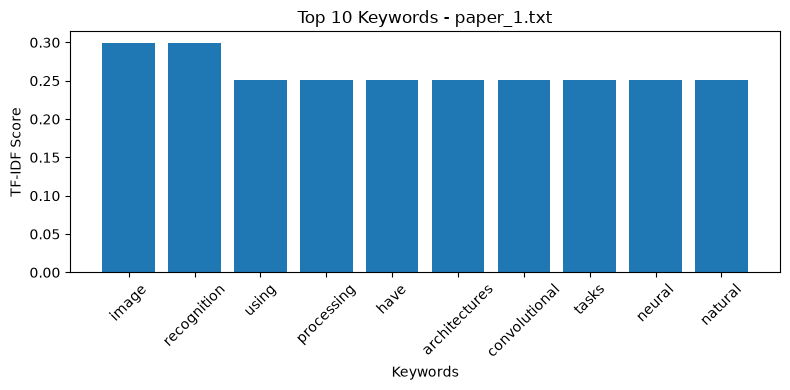

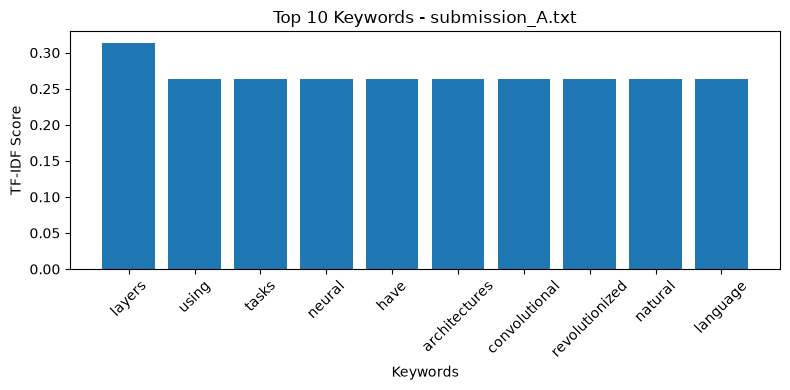

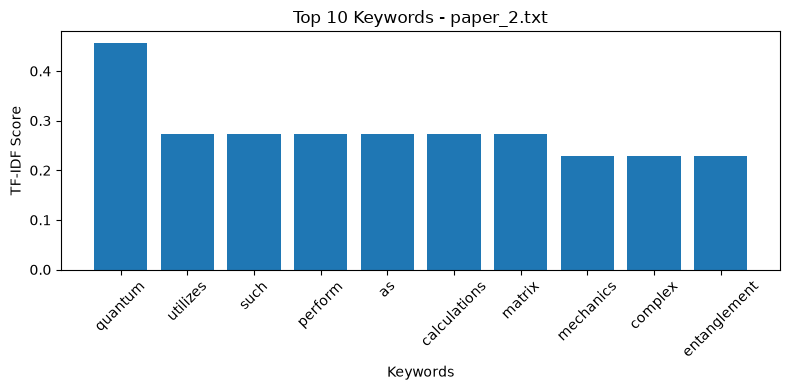

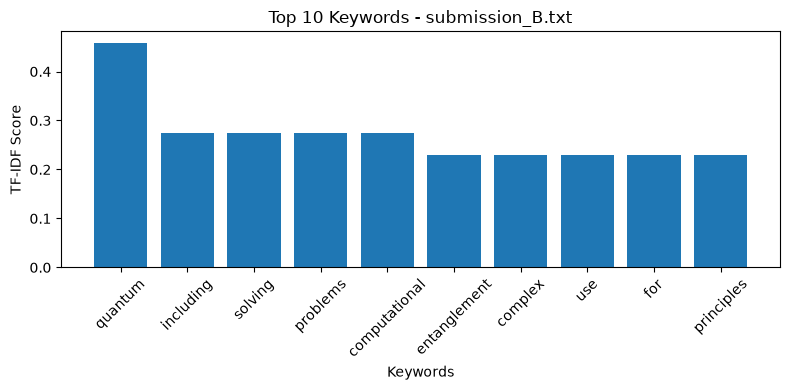

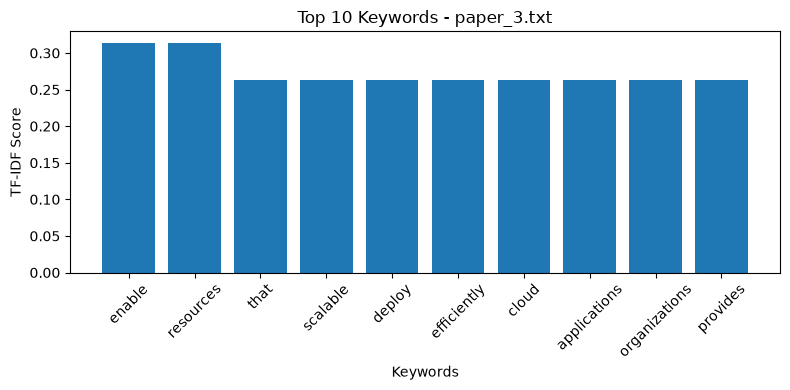

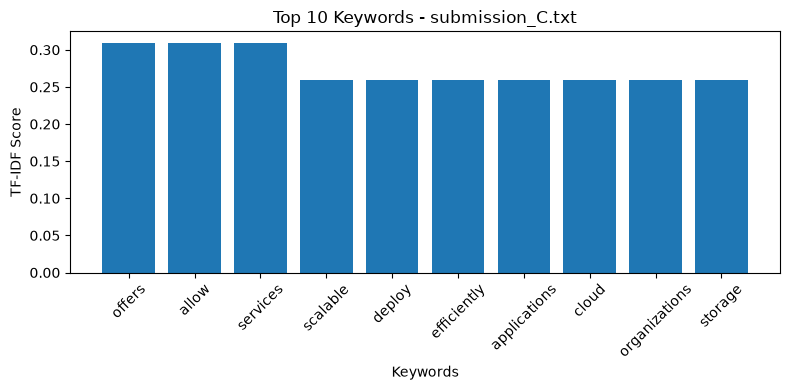

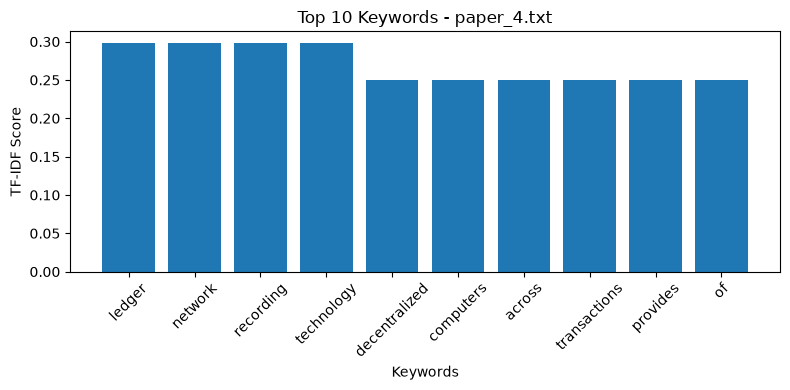

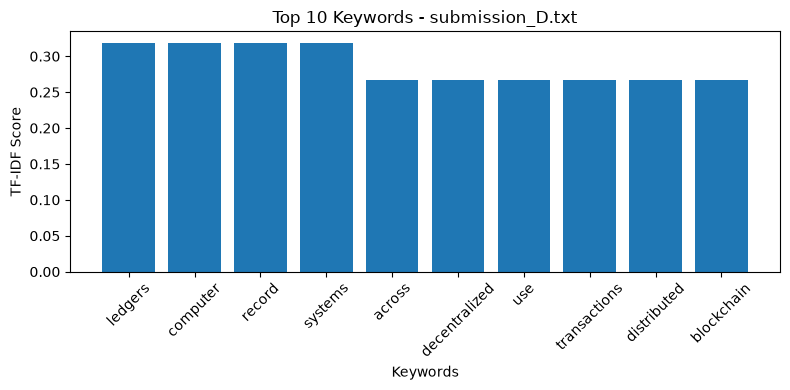

In [46]:

# Visualize top-N keywords for each document
for i, doc_id in enumerate(doc_ids):

    # Get TF-IDF scores for the document
    scores = tfidf_matrix[i]

    # Get indices of top N keywords
    top_indices = scores.argsort()[-N:][::-1]

    # Extract keywords and scores
    top_words = feature_names[top_indices]
    top_scores = scores[top_indices]

    # Create bar chart
    plt.figure(figsize=(8, 4))
    plt.bar(top_words, top_scores)

    plt.title(f"Top {N} Keywords - {doc_id}")
    plt.xlabel("Keywords")
    plt.ylabel("TF-IDF Score")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### Conclusion
- Hence, I have implemented the assignment by developing the Bag-of-Words and IF-IDF Vectorization and visualised the top-n keywords of each documents using bar chart.